# **AI METHODS I** · Day 4 assignment, Track B
## Damage segmentation in reinforced concrete

**Team:** Group 4 – Luis, Fawad, Hetashri, Daria · **Track:** B (fine-tuned YOLO26n-seg) · IAAC MaAI 2026/27

# 0. Introduction and problem definition

1. **Who uses it, for what?** A surveyor with hundreds of inspection photos of a concrete building or bridge. The model outlines damage on every photo, so the photos can be **ranked by severity** and an engineer looks at the worst ones first. It is a screening aid, not a structural assessment.
2. **What does a mistake cost?** A **missed** damage can delay finding a structural problem. A **false alarm** costs a few seconds of checking. So we favour recall, but a tool that flags everything saves no time.
3. **Compared with what?** (a) the pretrained YOLO26n-seg without fine-tuning, (b) simple hand-written rules as in notebook 02 ("dark thin lines = crack", "rust colour = corrosion").

**Data:** *Reinforced concrete structure segmentation dataset 2119*, Wang, J. (2026), Mendeley Data, V1, [doi:10.17632/2vkm6k4cfg.1](https://doi.org/10.17632/2vkm6k4cfg.1), **CC BY 4.0**. 2,119 photos with 3,124 polygons in 5 classes. One example = one photo with one or more class polygons (LabelMe JSON).

## 0.1 Setup
`TRAIN = False` skips training and downloads our weights from Hugging Face. `REUSE_RUNS = True` loads a finished run from `../runs/` instead of training it again.

In [1]:
import hashlib
import json
import math
import re
import shutil
import time
import zipfile
from pathlib import Path
import random

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
import yaml
from huggingface_hub import hf_hub_download
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
from ultralytics import YOLO

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA_DIR = Path("..") / "data"
FIG_DIR = Path("..") / "figures"
MODEL_DIR = Path("..") / "models"
RUNS_DIR = (Path("..") / "runs").resolve()   # Ultralytics needs an absolute path, else it writes to a global folder
for d in (DATA_DIR, FIG_DIR, MODEL_DIR):
    d.mkdir(exist_ok=True)

TRAIN = True        # False: no training, use the published weights from Hugging Face
REUSE_RUNS = True   # True: load a finished run from ../runs instead of training it again
HF_MODEL = "iaac-maai/day4-group4-rc-damage-segmentation"
BASE_MODEL = "yolo26n-seg.pt"   # YOLO26 nano segmentation, pretrained on COCO (downloaded by Ultralytics on first use)

DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
YOLO_DEVICE = 0 if DEVICE == "cuda" else DEVICE
print("device:", DEVICE, "| torch", torch.__version__)

plt.rcParams.update({"figure.dpi": 72, "savefig.dpi": 130, "axes.titleweight": "bold"})   # small inline figures, sharp exported PNGs


def save_fig(name, also_model_card=False, dpi=None):
    """Save the current figure to ../figures (and, for the model card, to ../models)."""
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=dpi)
    if also_model_card:
        plt.savefig(MODEL_DIR / f"{name}.png", bbox_inches="tight", dpi=dpi)

/Users/luiswulf/Documents/IAAC/AI-Methods/Group4-day4-assignment/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: mps | torch 2.15.0


# 1. Data and splits

## 1.1 Download
The three ZIP files come from Mendeley and are checked against the published SHA-256 checksums.

In [2]:
MENDELEY = "https://data.mendeley.com/public-files/datasets/2vkm6k4cfg/files"
FILES = {   # file name: (Mendeley file id, SHA-256 published by Mendeley)
    "imagedata.zip": ("e06f002e-47e7-477d-87e0-87bd02054c95", "d11697ed550fac8b42799f9bb39c00ca70736d1b5c88fcfd280c558c465c851d"),
    "jsondata.zip": ("ffcd179b-3772-43c4-ac5b-2236e075657a", "db2242e4dae9a36afd52cf0af7ad66654b4ddf8195eec75cb5780c5c432d3dd1"),
    "maskdata.zip": ("1380fe8e-8f6e-49d5-b217-08f1fe7729c5", "bd2c96de2b6a8eb90291062438661ddcf6b9a91f2bae500d98755423c0c1b1e8"),
}
RAW_DIR = DATA_DIR / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()


for name, (file_id, expected) in FILES.items():
    zip_path = RAW_DIR / name
    if not zip_path.exists():
        print("downloading", name)
        with requests.get(f"{MENDELEY}/{file_id}/file_downloaded", headers={"User-Agent": "Mozilla/5.0"}, stream=True, timeout=60) as response:
            response.raise_for_status()
            with open(zip_path, "wb") as f:
                shutil.copyfileobj(response.raw, f)
    assert sha256(zip_path) == expected, f"checksum mismatch for {name}"
    with zipfile.ZipFile(zip_path) as z:
        if not all((RAW_DIR / member).exists() for member in z.namelist()):
            z.extractall(RAW_DIR)

print(f"{len(list(RAW_DIR.glob('*.jpg')))} images, {len(list(RAW_DIR.glob('*.json')))} annotation files (LabelMe JSON)")

2119 images, 2119 annotation files (LabelMe JSON)


## 1.2 Look at the annotations
We read all polygons into one table per image and one per polygon. The **source family** (file-name pattern + image size) is used later to find copies.

| ID | Class | What counts |
|---|---|---|
| 0 | `crack` | a crack line, hairline to wide |
| 1 | `spalling` | concrete broken off, **no** visible rebar |
| 2 | `rebar_exposure` | visible rebar, not (or barely) rusted |
| 3 | `rebar_corrosion` | visible **rusted** rebar |
| 4 | `crushing` | concrete crushed under compression (column ends, joints) |

In [3]:
CLASSES = ["crack", "spalling", "rebar_exposure", "rebar_corrosion", "crushing"]
LABEL_MAP = {"Crack": 0, "Concrete spalling": 1, "Rebar exposure": 2, "Rebar corrosion": 3, "Concrete crushing": 4}
COLOURS = {0: (230, 25, 75), 1: (60, 180, 75), 2: (240, 50, 230), 3: (0, 130, 200), 4: (255, 200, 0)}   # RGB, as in the dataset masks


def polygon_area(points):
    x, y = points[:, 0], points[:, 1]
    return 0.5 * abs(np.dot(x, np.roll(y, 1)) - np.dot(y, np.roll(x, 1)))


image_rows, instance_rows = [], []
for jpg in sorted(RAW_DIR.glob("*.jpg")):
    annotation = json.loads(jpg.with_suffix(".json").read_text())
    width, height = Image.open(jpg).size
    family = f"{re.sub(r'[0-9]+', 'N', jpg.stem)} {width}x{height}"
    classes_here = []
    for shape in annotation["shapes"]:
        points = np.array(shape["points"], dtype=float)
        cls = LABEL_MAP[shape["label"]]
        classes_here.append(cls)
        instance_rows.append({"image": jpg.name, "cls": cls, "points": points, "n_points": len(points),
                              "area_share": polygon_area(points) / (width * height)})
    image_rows.append({"image": jpg.name, "width": width, "height": height, "family": family,
                       "n_instances": len(classes_here), "classes": sorted(set(classes_here))})

images = pd.DataFrame(image_rows)
instances = pd.DataFrame(instance_rows)
instances["class"] = instances["cls"].map(dict(enumerate(CLASSES)))
print(f"{len(images)} images, {len(instances)} polygons, {images.n_instances.eq(0).sum()} images without any polygon")
print(f"polygons per image: median {images.n_instances.median():.0f}, max {images.n_instances.max()}")
print(f"images with more than one class: {images.classes.map(len).gt(1).sum()}")
summary = instances.groupby("class").agg(polygons=("cls", "size"), images=("image", "nunique"),
                                         median_area_share=("area_share", "median")).reindex(CLASSES)
summary["median_area_share"] = (summary["median_area_share"] * 100).round(1).astype(str) + " %"
summary

2119 images, 3124 polygons, 0 images without any polygon
polygons per image: median 1, max 16
images with more than one class: 187


,polygons,images,median_area_share
class,,,
crack,1833,1315,2.7 %
spalling,282,184,0.7 %
rebar_exposure,89,82,27.7 %
rebar_corrosion,832,662,22.9 %
crushing,88,81,22.8 %


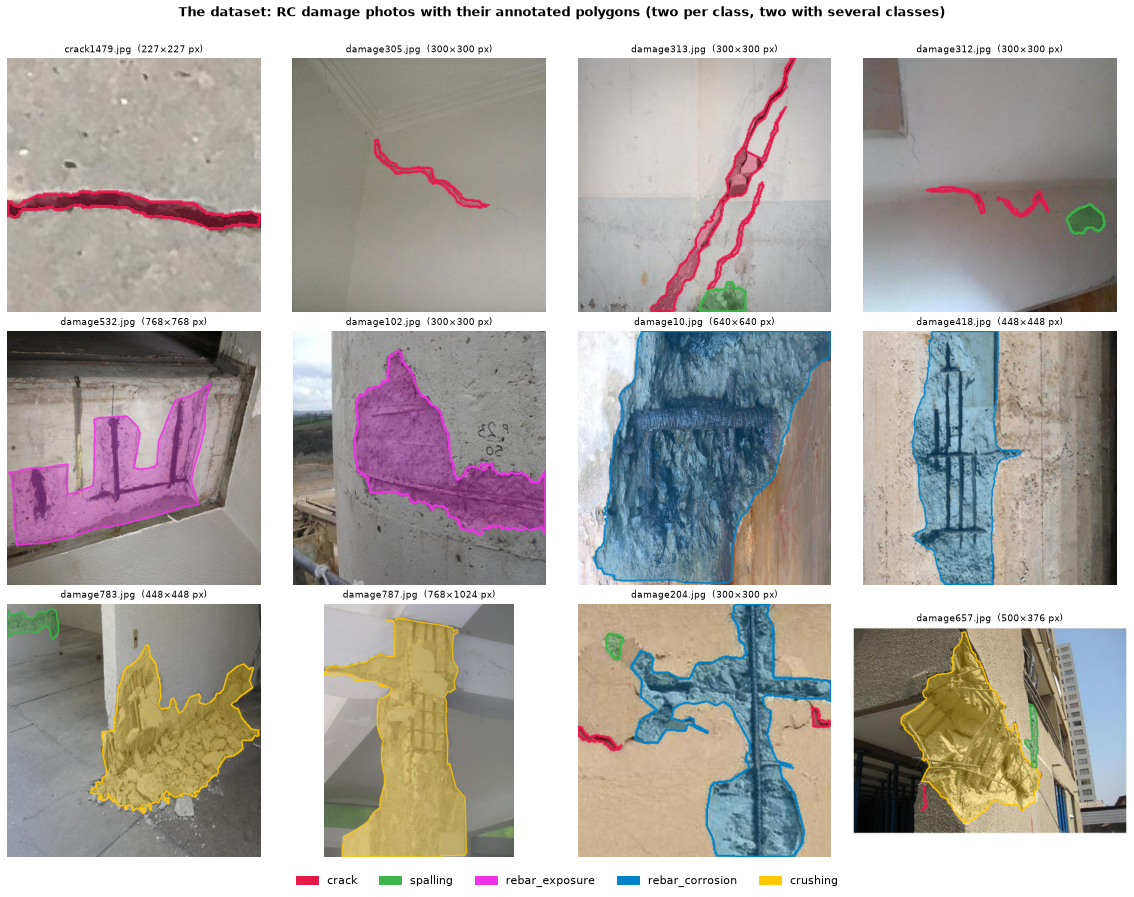

In [4]:
def draw_polygons(image, polys, thickness=None, fill_alpha=0.35):
    """Draw class-coloured polygons (list of (cls, Nx2 points in pixels)) on an RGB image."""
    out = image.copy()
    overlay = image.copy()
    t = thickness or max(2, int(round(max(image.shape[:2]) / 250)))
    for cls, points in polys:
        p = np.round(points).astype(np.int32).reshape(-1, 1, 2)
        cv2.fillPoly(overlay, [p], COLOURS[cls])
        cv2.polylines(out, [p], True, COLOURS[cls], t)
    return cv2.addWeighted(overlay, fill_alpha, out, 1 - fill_alpha, 0)


def load_rgb(path, max_side=None):
    image = np.asarray(Image.open(path).convert("RGB"))
    if max_side and max(image.shape[:2]) > max_side:
        s = max_side / max(image.shape[:2])
        image = cv2.resize(image, (round(image.shape[1] * s), round(image.shape[0] * s)), interpolation=cv2.INTER_AREA)
    return image


def class_legend(ax, loc="lower center", ncol=5, **kw):
    handles = [plt.Rectangle((0, 0), 1, 1, color=np.array(COLOURS[k]) / 255) for k in range(len(CLASSES))]
    ax.legend(handles, CLASSES, loc=loc, ncol=ncol, frameon=False, **kw)


rng = np.random.default_rng(SEED)
examples = []
for k in range(len(CLASSES)):   # two images per class, plus two with several classes
    pool = images[images.classes.map(lambda c: k in c)].image.tolist()
    examples += list(rng.choice(pool, 2, replace=False))
examples += list(rng.choice(images[images.classes.map(len) >= 3].image.tolist(), 2, replace=False))

fig, axes = plt.subplots(3, 4, figsize=(16, 12.6))
for ax, name in zip(axes.flat, examples):
    image = load_rgb(RAW_DIR / name)
    polys = [(r.cls, r.points) for r in instances[instances.image == name].itertuples()]
    ax.imshow(draw_polygons(image, polys))
    ax.set_title(f"{name}  ({image.shape[1]}×{image.shape[0]} px)", fontsize=9, fontweight="normal")
    ax.axis("off")
fig.suptitle("The dataset: RC damage photos with their annotated polygons (two per class, two with several classes)", fontsize=13, fontweight="bold")
class_legend(fig, loc="lower center", fontsize=11)
plt.tight_layout(rect=(0, 0.03, 1, 0.97))
save_fig("01_dataset_examples", dpi=90)
plt.show()

**What we see:** very mixed images, from 227 px crack close-ups to whole columns after earthquakes. Cracks are 59 % of all polygons and thin. Spalling patches are small, rebar and crushing areas are large. Annotation style varies: one long crack is sometimes split into several polygons.

## 1.3 Before splitting: the same photo appears several times

The images were collected from other public datasets, and many are **augmented copies** (flipped, rotated, cropped, re-coloured). If copies land in both training and test, the test measures memory, not skill.

We link two images if (thresholds chosen by looking at pairs):
1. their **perceptual hash** (256 bits, checked under all 8 rotations/mirrors) differs by ≤ 30 bits, or
2. their **ResNet18 features** have cosine similarity ≥ 0.95 (≥ 0.90 if one image shows more than a crack), or
3. same source family, file numbers ≤ 5 apart, and they look alike, or
4. they belong to the `crackN 4032x3024` family (35 photos of one slab).

Linked images form a **group**, and a group stays in one split.

In [5]:
from torchvision import models as tv_models

HASH_THRESHOLD, SERIES_THRESHOLD, SERIES_GAP = 30, 60, 5
CNN_THRESHOLD, CNN_THRESHOLD_DAMAGE = 0.95, 0.90


def dihedral_hashes(path):
    """256-bit difference hash of the 8 rotations / mirror images of an image (8 x 32 bytes)."""
    grey = np.asarray(Image.open(path).convert("L").resize((64, 64)), dtype=np.uint8)
    hashes = []
    for k in range(4):
        rotated = np.rot90(grey, k)
        for variant in (rotated, rotated[:, ::-1]):
            small = np.asarray(Image.fromarray(np.ascontiguousarray(variant)).resize((17, 16)), dtype=np.int16)
            hashes.append(np.packbits(small[:, 1:] > small[:, :-1]))
    return np.stack(hashes)


start = time.time()
n = len(images)
hashes = np.stack([dihedral_hashes(RAW_DIR / name) for name in images.image])    # n x 8 x 32 bytes
distance = np.full((n, n), 256, dtype=np.int32)
for t in range(8):   # smallest number of different bits over the 8 transforms
    distance = np.minimum(distance, np.bitwise_count(hashes[:, t][:, None, :] ^ hashes[:, 0][None, :, :]).sum(-1))
distance = np.minimum(distance, distance.T)
np.fill_diagonal(distance, 256)

weights = tv_models.ResNet18_Weights.DEFAULT
encoder = tv_models.resnet18(weights=weights)
encoder.fc = torch.nn.Identity()            # keep the 512 features, drop the ImageNet classifier
encoder.eval().to(DEVICE)
preprocess = weights.transforms()
features = []
with torch.no_grad():
    for k in range(0, n, 64):
        batch = torch.stack([preprocess(Image.open(RAW_DIR / name).convert("RGB")) for name in images.image[k:k + 64]]).to(DEVICE)
        variants = []
        for r in range(4):
            rotated = torch.rot90(batch, r, dims=(2, 3))
            variants += [encoder(rotated), encoder(torch.flip(rotated, dims=(3,)))]
        features.append(torch.nn.functional.normalize(torch.stack(variants, 1), dim=-1).cpu())
features = torch.cat(features).numpy()                                            # n x 8 x 512
similarity = np.einsum("itd,jd->ijt", features, features[:, 0]).max(axis=2)       # best match over the 8 transforms
similarity = np.maximum(similarity, similarity.T)
np.fill_diagonal(similarity, 0)

number = images.image.str.extract(r"(\d+)")[0].astype(float).values
family = images.family.to_numpy(dtype=str)
not_only_crack = images.classes.map(lambda c: any(k != 0 for k in c)).values
same_series = (family[:, None] == family[None, :]) & (np.abs(number[:, None] - number[None, :]) <= SERIES_GAP)
rules = {
    "1 hash <= 30 bits": distance <= HASH_THRESHOLD,
    "2 CNN >= 0.95": similarity >= CNN_THRESHOLD,
    "3 CNN >= 0.90, not only cracks": (similarity >= CNN_THRESHOLD_DAMAGE) & (not_only_crack[:, None] | not_only_crack[None, :]),
    "4 close numbers, alike": same_series & ((distance <= SERIES_THRESHOLD) | (similarity >= CNN_THRESHOLD_DAMAGE)),
}
link = np.logical_or.reduce(list(rules.values()))
slab = np.where(family == "crackN 4032x3024")[0]
link[slab[0], slab[1:]] = True                                                    # rule 5

parent = list(range(n))   # union-find: images connected by links end up with the same root


def root(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i


for i, j in zip(*np.where(np.triu(link, 1))):
    parent[root(i)] = root(j)
images["group"] = [root(i) for i in range(n)]
group_sizes = images.groupby("group").size()
print(f"hashing, CNN features and comparing {n} images took {time.time() - start:.0f} s")
print("linked pairs per rule:", {name: int(np.triu(r, 1).sum()) for name, r in rules.items()})
print(f"-> {len(group_sizes)} groups: {(group_sizes == 1).sum()} single images and {(group_sizes > 1).sum()} groups of "
      f"2-{group_sizes.max()} images, holding {group_sizes[group_sizes > 1].sum()} images "
      f"({group_sizes[group_sizes > 1].sum() / n:.0%} of the dataset)")

hashing, CNN features and comparing 2119 images took 47 s
linked pairs per rule: {'1 hash <= 30 bits': 2313, '2 CNN >= 0.95': 2513, '3 CNN >= 0.90, not only cracks': 2202, '4 close numbers, alike': 1826}
-> 736 groups: 477 single images and 259 groups of 2-119 images, holding 1642 images (77% of the dataset)


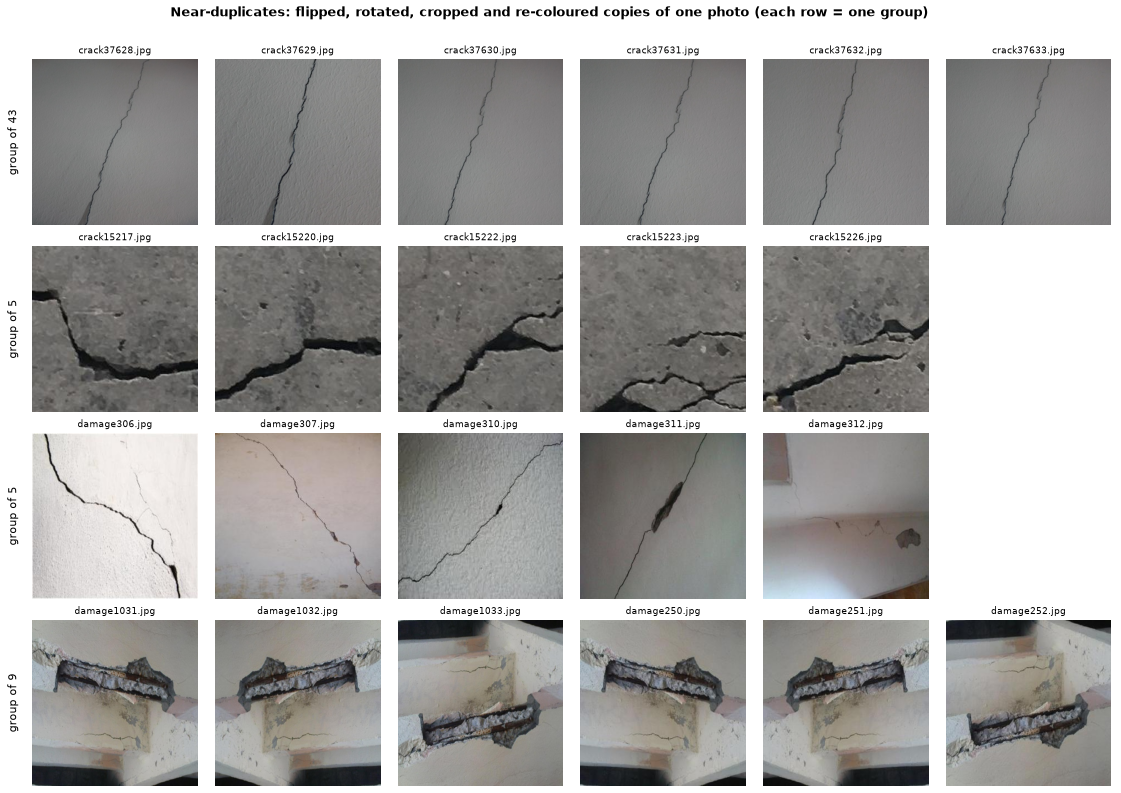

In [6]:
big_groups = group_sizes[group_sizes >= 4].sample(4, random_state=SEED).index
fig, axes = plt.subplots(4, 6, figsize=(16, 11.2))
for row, g in zip(axes, big_groups):
    members = images[images.group == g].image.tolist()
    for ax in row:
        ax.axis("off")
    for ax, name in zip(row, members[:6]):
        ax.imshow(load_rgb(RAW_DIR / name, 400))
        ax.set_title(name, fontsize=9, fontweight="normal")
    row[0].text(-0.08, 0.5, f"group of {len(members)}", transform=row[0].transAxes, rotation=90, va="center", ha="right", fontsize=11)
fig.suptitle("Near-duplicates: flipped, rotated, cropped and re-coloured copies of one photo (each row = one group)", fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0.02, 0, 1, 0.97))
save_fig("02_duplicate_groups", dpi=90)
plt.show()

**What we see:** each row is one photo repeated several times. **77 % of the images belong to a group**; only 736 independent groups remain. A random split would put copies into the test set.

## 1.4 Split by group, before anything else
`StratifiedGroupKFold` splits the groups into **train ≈ 72 %, validation ≈ 14 %, test ≈ 14 %**, stratified by the rarest class in each image so that every split gets some crushing and exposed rebar. The test set is used once, in section 6.

In [7]:
RARITY = [4, 2, 1, 3, 0]   # crushing, rebar_exposure, spalling, rebar_corrosion, crack: rarest first
images["stratum"] = images.classes.map(lambda c: next(k for k in RARITY if k in c))

outer = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
rest_idx, test_idx = next(outer.split(images, images.stratum, images.group))
rest = images.iloc[rest_idx]
inner = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=SEED)
train_idx, val_idx = next(inner.split(rest, rest.stratum, rest.group))
images["split"] = "train"
images.loc[rest.index[val_idx], "split"] = "val"
images.loc[images.index[test_idx], "split"] = "test"
assert images.groupby("group").split.nunique().max() == 1, "a group is spread over two splits"

instances = instances.merge(images[["image", "split"]], on="image")
SPLITS = ["train", "val", "test"]
table = instances.pivot_table(index="class", columns="split", values="cls", aggfunc="size").reindex(index=CLASSES, columns=SPLITS)
table.loc["images"] = images.split.value_counts().reindex(SPLITS)

# leakage check: how similar is each test image to its closest training image?
is_train, is_test = (images.split == "train").values, (images.split == "test").values
nearest = similarity[np.ix_(is_test, is_train)].max(axis=1)
print(f"test images with a training image of CNN similarity >= 0.90: {(nearest >= 0.90).sum()} of {is_test.sum()}")
table

test images with a training image of CNN similarity >= 0.90: 144 of 303


split,train,val,test
class,,,
crack,1271,279,283
spalling,213,35,34
rebar_exposure,65,12,12
rebar_corrosion,628,106,98
crushing,62,15,11
images,1513,303,303


No group is split. About half of the test images are still *similar* (similarity 0.90–0.95) to a training image: almost all are plain crack close-ups, which look alike even when they show different walls. Grouping them too would chain everything into one giant group, so we accept it and keep it in mind: **the crack score is probably optimistic for a new building.**

## 1.5 Export in YOLO format
One text file per image, one line per polygon (`class x1 y1 x2 y2 …`, normalised to 0–1). The images are **copied** into `data/yolo.nosync/` (iCloud Drive deleted hard-linked images during our first training runs; `.nosync` folders are not synced).

In [8]:
YOLO_DIR = DATA_DIR / "yolo.nosync"   # ".nosync": not synced by iCloud Drive
if YOLO_DIR.exists():
    shutil.rmtree(YOLO_DIR)
for split in SPLITS:
    (YOLO_DIR / "images" / split).mkdir(parents=True)
    (YOLO_DIR / "labels" / split).mkdir(parents=True)

for row in images.itertuples():
    source, target = RAW_DIR / row.image, YOLO_DIR / "images" / row.split / row.image
    shutil.copy2(source, target)
    lines = []
    for inst in instances[instances.image == row.image].itertuples():
        xy = (inst.points / [row.width, row.height]).clip(0, 1)
        if len(xy) >= 3:
            lines.append(f"{inst.cls} " + " ".join(f"{v:.6f}" for v in xy.flatten()))
    (YOLO_DIR / "labels" / row.split / f"{Path(row.image).stem}.txt").write_text("\n".join(lines) + "\n")

DATA_YAML = YOLO_DIR / "data.yaml"
DATA_YAML.write_text(yaml.safe_dump({"path": str(YOLO_DIR.resolve()), "train": "images/train", "val": "images/val",
                                     "test": "images/test", "names": dict(enumerate(CLASSES))}, sort_keys=False))
images[["image", "family", "group", "split"]].to_csv(DATA_DIR / "split.csv", index=False)
print(DATA_YAML.read_text())
print({s: len(list((YOLO_DIR / "images" / s).iterdir())) for s in SPLITS})

path: /Users/luiswulf/Documents/IAAC/AI-Methods/Group4-day4-assignment/data/yolo.nosync
train: images/train
val: images/val
test: images/test
names:
  0: crack
  1: spalling
  2: rebar_exposure
  3: rebar_corrosion
  4: crushing

{'train': 1513, 'val': 303, 'test': 303}


# 2. Baseline

1. **Pretrained YOLO26n-seg** (COCO, 80 everyday classes): does it already find damage?
2. **Rules** as in notebook 02: crack = dark, thin, elongated pixels; corrosion = rust-coloured pixels (HSV). Parameters chosen on validation.

Rules give pixel masks, not objects, so we compare them with **pixel IoU per class** (overlap / union of all predicted and true pixels).

In [9]:
WORK_SIDE = 640    # pixel IoU is computed at this resolution (longest side), for speed
val_names = images.loc[images.split == "val", "image"].tolist()
test_names = images.loc[images.split == "test", "image"].tolist()


def true_class_masks(name, shape):
    """One boolean mask per class from the annotated polygons, at the size `shape` (h, w)."""
    row = images.loc[images.image == name].iloc[0]
    sx, sy = shape[1] / row.width, shape[0] / row.height
    masks = np.zeros((len(CLASSES),) + shape, dtype=np.uint8)
    for inst in instances[instances.image == name].itertuples():
        cv2.fillPoly(masks[inst.cls], [np.round(inst.points * [sx, sy]).astype(np.int32)], 1)
    return masks.astype(bool)


def truth_polys(name, shape):
    width = images.loc[images.image == name, "width"].iloc[0]
    return [(r.cls, r.points * shape[1] / width) for r in instances[instances.image == name].itertuples()]


def rule_crack(rgb, block=15, c=18, min_area=60, min_elongation=8.0):
    """Crack = dark, thin, elongated pixels (adaptive threshold + shape filter), as in notebook 02."""
    grey = cv2.GaussianBlur(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY), (5, 5), 0)
    dark = cv2.adaptiveThreshold(grey, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY_INV, block, c)
    dark = cv2.morphologyEx(dark, cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))
    count, labels, stats, _ = cv2.connectedComponentsWithStats(dark)
    keep = np.zeros(count, bool)
    for k in range(1, count):
        area, w, h = stats[k, cv2.CC_STAT_AREA], stats[k, cv2.CC_STAT_WIDTH], stats[k, cv2.CC_STAT_HEIGHT]
        keep[k] = area >= min_area and max(w, h) ** 2 / area >= min_elongation   # long and thin, not a blob
    return keep[labels]


def rule_rust(rgb, hue=(2, 25), min_saturation=70, value=(50, 230), min_area=80):
    """Rebar corrosion = rust-coloured pixels (orange-brown hue, saturated), like the colour rules of notebook 02."""
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV)
    mask = cv2.inRange(hsv, (hue[0], min_saturation, value[0]), (hue[1], 255, value[1]))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
    count, labels, stats, _ = cv2.connectedComponentsWithStats(mask)
    keep = np.r_[False, stats[1:, cv2.CC_STAT_AREA] >= min_area]
    return keep[labels]


def rule_masks(name, rgb):
    return {0: rule_crack(rgb), 3: rule_rust(rgb)}


def pixel_iou(names, predict_masks, classes=range(len(CLASSES))):
    """Pixel IoU per class over a set of images: sum of intersections / sum of unions.
    predict_masks(name, rgb) returns {class id: boolean mask}."""
    inter, union = np.zeros(len(CLASSES)), np.zeros(len(CLASSES))
    for name in names:
        rgb = load_rgb(RAW_DIR / name, WORK_SIDE)
        truth = true_class_masks(name, rgb.shape[:2])
        predicted = predict_masks(name, rgb)
        for k in classes:
            p = predicted.get(k, np.zeros(rgb.shape[:2], bool))
            inter[k] += (p & truth[k]).sum()
            union[k] += (p | truth[k]).sum()
    return {CLASSES[k]: inter[k] / max(union[k], 1) for k in classes}


rule_val = pixel_iou(val_names, rule_masks, classes=[0, 3])
print("Rules, pixel IoU on the validation set:", {k: round(v, 3) for k, v in rule_val.items()})

Rules, pixel IoU on the validation set: {'crack': np.float64(0.159), 'rebar_corrosion': np.float64(0.177)}


In [10]:
coco = YOLO(BASE_MODEL)
coco_found, coco_images = [], 0
for name in val_names:
    result = coco.predict(str(RAW_DIR / name), conf=0.25, device=YOLO_DEVICE, verbose=False)[0]
    coco_found += [coco.names[int(c)] for c in result.boxes.cls]
    coco_images += len(result.boxes) > 0
print(f"Pretrained COCO model on the {len(val_names)} validation images: {len(coco_found)} objects on {coco_images} images.")
print("None of its 80 classes is a type of damage, so its AP for all 5 damage classes is 0. What it does report:")
pd.Series(coco_found, dtype=str).value_counts().head(8).rename("detections").to_frame()

Pretrained COCO model on the 303 validation images: 85 objects on 76 images.
None of its 80 classes is a type of damage, so its AP for all 5 damage classes is 0. What it does report:


,detections
giraffe,22
kite,15
horse,12
teddy bear,9
person,7
bird,5
book,4
dog,2


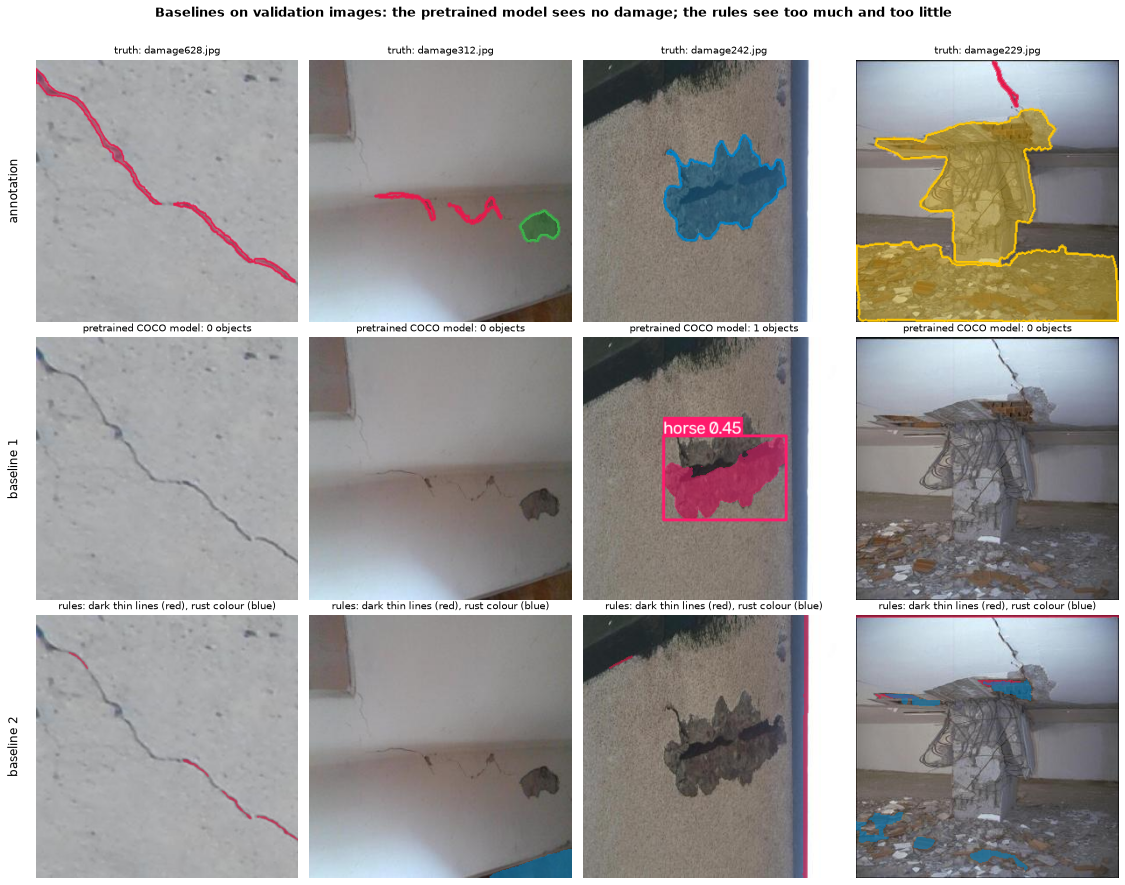

In [11]:
# one validation image each with a crack, spalling, rebar corrosion and crushing
baseline_examples = [rng.choice(images[(images.split == "val") & images.classes.map(lambda c, k=k: k in c)].image.tolist())
                     for k in [0, 1, 3, 4]]
fig, axes = plt.subplots(3, 4, figsize=(16, 12.5))
for col, name in enumerate(baseline_examples):
    rgb = load_rgb(RAW_DIR / name, WORK_SIDE)
    polys = truth_polys(name, rgb.shape[:2])
    axes[0, col].imshow(draw_polygons(rgb, polys))
    axes[0, col].set_title(f"truth: {name}", fontsize=10, fontweight="normal")
    coco_result = coco.predict(rgb[:, :, ::-1].copy(), conf=0.25, device=YOLO_DEVICE, verbose=False)[0]
    axes[1, col].imshow(coco_result.plot(line_width=2)[:, :, ::-1])
    axes[1, col].set_title(f"pretrained COCO model: {len(coco_result.boxes)} objects", fontsize=10, fontweight="normal")
    rules = rule_masks(name, rgb)
    shown = rgb.copy()
    for k, m in rules.items():
        shown[m] = (0.4 * shown[m] + 0.6 * np.array(COLOURS[k])).astype(np.uint8)
    axes[2, col].imshow(shown)
    axes[2, col].set_title("rules: dark thin lines (red), rust colour (blue)", fontsize=10, fontweight="normal")
for ax in axes.flat:
    ax.axis("off")
for row, label in enumerate(["annotation", "baseline 1", "baseline 2"]):
    axes[row, 0].text(-0.06, 0.5, label, transform=axes[row, 0].transAxes, rotation=90, va="center", ha="right", fontsize=12)
fig.suptitle("Baselines on validation images: the pretrained model sees no damage; the rules see too much and too little", fontsize=13, fontweight="bold")
plt.tight_layout(rect=(0.02, 0, 1, 0.97))
save_fig("03_baselines", dpi=90)
plt.show()

**What we see:** the pretrained model finds no damage at all, only *giraffes*, *kites* and *teddy bears* on rubble and walls, so its AP is 0. The rules reach pixel IoU 0.16 (cracks) and 0.18 (corrosion) on validation: they catch fragments of cracks but also every dark edge, and anything brown counts as rust.

# 3. The model and its training

**YOLO26n-seg** (3.1 M parameters, pretrained on COCO), all layers fine-tuned, trained locally on an Apple M4 (`mps`).

| Setting | Value |
|---|---|
| epochs / patience | 50 / 15 (early stopping) |
| image size / batch | 640 px / 16 |
| augmentation | Ultralytics defaults (flips, scaling, colour, mosaic) |
| weights kept | `best.pt` (best validation epoch) |
| seed | 42 |

In [12]:
TRAIN_SETTINGS = dict(epochs=50, batch=16, patience=15, workers=4, seed=SEED, deterministic=True, plots=True, verbose=False)
MAIN_RUN, MAIN_IMGSZ = "seg_n_640", 640


def train_run(name, imgsz):
    """Train one run (or reuse a finished one) and return the path of its best weights and its training log."""
    run_dir = RUNS_DIR / name
    best, log, minutes = run_dir / "weights" / "best.pt", run_dir / "results.csv", run_dir / "training_minutes.txt"
    if REUSE_RUNS and best.exists() and minutes.exists():
        print(f"{name}: reusing the finished run in {run_dir} (trained in {float(minutes.read_text()):.0f} min)")
    elif not TRAIN:
        local = MODEL_DIR / "downloaded"
        best = Path(hf_hub_download(HF_MODEL, "model.pt", local_dir=local))
        log = Path(hf_hub_download(HF_MODEL, "results.csv", local_dir=local))
        print(f"{name}: TRAIN = False, using the published model from https://huggingface.co/{HF_MODEL}")
    else:
        start = time.time()
        YOLO(BASE_MODEL).train(data=str(DATA_YAML), imgsz=imgsz, device=YOLO_DEVICE, project=str(RUNS_DIR), name=name,
                               exist_ok=True, **TRAIN_SETTINGS)
        minutes.write_text(f"{(time.time() - start) / 60:.1f}")
        print(f"{name}: training took {(time.time() - start) / 60:.0f} min")
    return best, log


main_best, main_log = train_run(MAIN_RUN, MAIN_IMGSZ)
model = YOLO(main_best)
print("classes:", model.names)
print(f"parameters: {sum(p.numel() for p in model.model.parameters()):,}")

seg_n_640: reusing the finished run in /Users/luiswulf/Documents/IAAC/AI-Methods/Group4-day4-assignment/runs/seg_n_640 (trained in 90 min)
classes: {0: 'crack', 1: 'spalling', 2: 'rebar_exposure', 3: 'rebar_corrosion', 4: 'crushing'}
parameters: 3,084,955


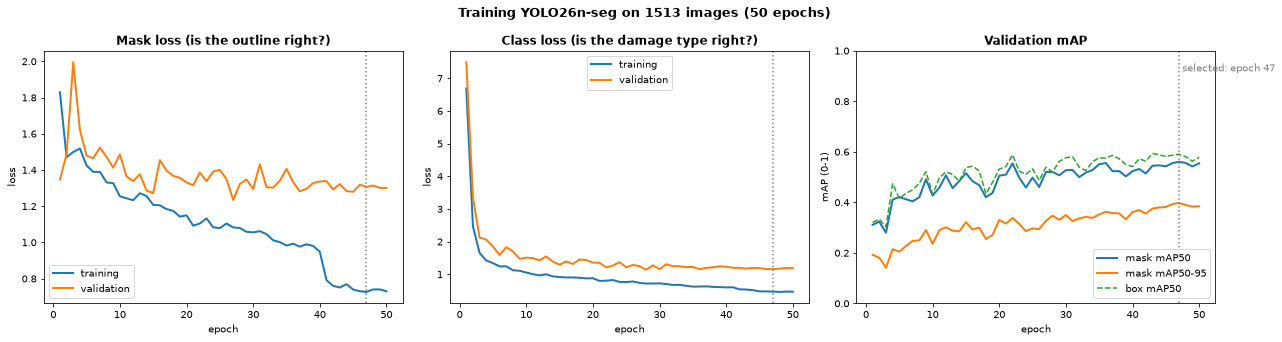

,epoch,train/seg_loss,val/seg_loss,val/cls_loss,metrics/mAP50(M),metrics/mAP50-95(M),metrics/mAP50(B)
0,1,1.829,1.347,7.492,0.311,0.192,0.320
4,5,1.425,1.479,1.854,0.421,0.205,0.415
9,10,1.254,1.486,1.512,0.427,0.236,0.433
19,20,1.149,1.331,1.359,0.506,0.330,0.531
46,47,0.726,1.306,1.158,0.561,0.397,0.590
49,50,0.730,1.301,1.188,0.554,0.384,0.578


In [13]:
history = pd.read_csv(main_log)
history.columns = history.columns.str.strip()
history["fitness"] = history["metrics/mAP50-95(M)"] + history["metrics/mAP50-95(B)"]
best_epoch = int(history.loc[history.fitness.idxmax(), "epoch"])

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, (loss, title) in zip(axes[:2], [("seg_loss", "Mask loss (is the outline right?)"), ("cls_loss", "Class loss (is the damage type right?)")]):
    ax.plot(history.epoch, history[f"train/{loss}"], lw=2, label="training")
    ax.plot(history.epoch, history[f"val/{loss}"], lw=2, label="validation")
    ax.set(title=title, xlabel="epoch", ylabel="loss")
    ax.legend()
axes[2].plot(history.epoch, history["metrics/mAP50(M)"], lw=2, label="mask mAP50")
axes[2].plot(history.epoch, history["metrics/mAP50-95(M)"], lw=2, label="mask mAP50-95")
axes[2].plot(history.epoch, history["metrics/mAP50(B)"], lw=1.5, ls="--", label="box mAP50")
axes[2].set(title="Validation mAP", xlabel="epoch", ylabel="mAP (0-1)", ylim=(0, 1))
for ax in axes:
    ax.axvline(best_epoch, color="grey", ls=":", lw=1.5)
axes[2].text(best_epoch, 0.95, f" selected: epoch {best_epoch}", color="grey", va="top")
axes[2].legend(loc="lower right")
fig.suptitle(f"Training YOLO26n-seg on {int(table.loc['images', 'train'])} images ({len(history)} epochs)", fontsize=13, fontweight="bold")
plt.tight_layout()
save_fig("04_training_curves", also_model_card=True)
plt.show()
rows_to_show = sorted({0, 4, 9, 19, best_epoch - 1, len(history) - 1} & set(range(len(history))))
history[["epoch", "train/seg_loss", "val/seg_loss", "val/cls_loss", "metrics/mAP50(M)", "metrics/mAP50-95(M)", "metrics/mAP50(B)"]].iloc[rows_to_show].round(3)

**Reading the curves:**
- Fast learning at the start (mask mAP50 0.31 → 0.51 in 20 epochs), then slow to **0.56 at epoch 47** (the kept weights).
- The training loss keeps falling, the validation mask loss stays flat after about 20 epochs: **beginning overfitting**. More varied data would help more than more epochs.
- The drop of the training loss at epoch 41 is the end of the mosaic augmentation.

# 4. Look inside and diagnose (validation set)

A prediction counts as correct if its class is right and its mask overlaps the true mask with IoU ≥ 0.5 (mAP50).

In [14]:
def per_class_table(metrics):
    index = list(metrics.seg.ap_class_index)
    rows = {}
    for k, name in enumerate(CLASSES):
        if k in index:
            i = index.index(k)
            rows[name] = {"mask precision": metrics.seg.p[i], "mask recall": metrics.seg.r[i], "mask AP50": metrics.seg.ap50[i],
                          "mask AP50-95": metrics.seg.ap[i], "box AP50": metrics.box.ap50[i]}
    return pd.DataFrame(rows).T.round(3)


val_metrics = model.val(data=str(DATA_YAML), split="val", imgsz=MAIN_IMGSZ, device=YOLO_DEVICE, project=str(RUNS_DIR),
                        name=f"{MAIN_RUN}_val", exist_ok=True, plots=False, verbose=False)
print(f"VALIDATION: mask mAP50 = {val_metrics.seg.map50:.3f}, mask mAP50-95 = {val_metrics.seg.map:.3f}, "
      f"box mAP50 = {val_metrics.box.map50:.3f}")
val_per_class = per_class_table(val_metrics)
val_per_class.assign(polygons=table["val"].drop("images"))

Ultralytics 8.4.210 🚀 Python-3.12.10 torch-2.15.0 MPS (Apple M4)


YOLO26n-seg summary (fused): 137 layers, 2,704,755 parameters, 0 gradients, 9.1 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 262.0±235.2 MB/s, size: 9.4 KB)


val: Scanning /Users/luiswulf/Documents/IAAC/AI-Methods/Group4-day4-assignment/data/yolo.nosync/labels/val... 303 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 303/303 5.0Kit/s 0.1s

val: New cache created: /Users/luiswulf/Documents/IAAC/AI-Methods/Group4-day4-assignment/data/yolo.nosync/labels/val.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 5% ╸─────────── 1/19 1.5s/it 0.5s<27.2s

... (18 outputs left out)

                   all        303        447      0.494      0.629      0.591      0.415      0.479      0.614      0.561      0.396


Speed: 0.2ms preprocess, 2.1ms inference, 0.0ms loss, 10.7ms postprocess per image


VALIDATION: mask mAP50 = 0.561, mask mAP50-95 = 0.396, box mAP50 = 0.591


,mask precision,mask recall,mask AP50,mask AP50-95,box AP50,polygons
crack,0.607,0.771,0.761,0.404,0.782,279
spalling,0.379,0.686,0.465,0.342,0.451,35
rebar_exposure,0.208,0.134,0.181,0.143,0.205,12
rebar_corrosion,0.601,0.811,0.801,0.716,0.837,106
crushing,0.598,0.667,0.598,0.376,0.678,15


To look at single mistakes we match predictions and true polygons ourselves (mask IoU ≥ 0.5, most confident first): unmatched predictions are **false alarms**, unmatched polygons are **missed**. The same cache is reused for the threshold sweep in section 6.

In [15]:
def true_instances(name, shape):
    """The true polygons of an image as (class, boolean mask, share of the image) at the size `shape`."""
    row = images.loc[images.image == name].iloc[0]
    sx, sy = shape[1] / row.width, shape[0] / row.height
    out = []
    for inst in instances[instances.image == name].itertuples():
        m = np.zeros(shape, np.uint8)
        cv2.fillPoly(m, [np.round(inst.points * [sx, sy]).astype(np.int32)], 1)
        out.append((inst.cls, m.astype(bool), inst.area_share))
    return out


def predict_cache(detector, names, imgsz, folder=RAW_DIR, with_truth=True):
    """Predict once at confidence 0.01 and keep classes, confidences, outlines (at WORK_SIDE) and mask IoUs with the truth."""
    cache = {}
    for name in names:
        rgb = load_rgb(folder / name, WORK_SIDE)
        result = detector.predict(str(folder / name), conf=0.01, imgsz=imgsz, max_det=100, device=YOLO_DEVICE, verbose=False)[0]
        sx, sy = rgb.shape[1] / result.orig_shape[1], rgb.shape[0] / result.orig_shape[0]
        polys = [np.round(p * [sx, sy]).astype(np.int32) for p in result.masks.xy] if result.masks is not None else []
        entry = {"shape": rgb.shape[:2], "cls": result.boxes.cls.cpu().numpy().astype(int),
                 "conf": result.boxes.conf.cpu().numpy(), "polys": polys}
        if with_truth:
            truth = true_instances(name, rgb.shape[:2])
            entry["true_cls"] = np.array([t[0] for t in truth], dtype=int)
            entry["true_area"] = np.array([t[2] for t in truth])
            iou_any = np.zeros((len(polys), len(truth)))     # mask IoU of every prediction with every true polygon
            for i, p in enumerate(polys):
                if len(p) < 3:
                    continue
                pm = np.zeros(rgb.shape[:2], np.uint8)
                cv2.fillPoly(pm, [p], 1)
                pm = pm.astype(bool)
                for j, (_, tm, _) in enumerate(truth):
                    iou_any[i, j] = (pm & tm).sum() / max((pm | tm).sum(), 1)
            entry["iou_any"] = iou_any
            entry["iou"] = iou_any * (entry["cls"][:, None] == entry["true_cls"][None, :])   # same class only
        cache[name] = entry
    return cache


def match(entry, threshold, iou_threshold=0.5):
    """Greedy matching at a confidence threshold: returns (TP flags of kept predictions, kept indices, matched truth flags)."""
    keep = np.where(entry["conf"] >= threshold)[0]
    keep = keep[np.argsort(-entry["conf"][keep])]
    matched = np.zeros(len(entry["true_cls"]), bool)
    tp = np.zeros(len(keep), bool)
    for n_, i in enumerate(keep):
        candidates = np.where(~matched & (entry["iou"][i] >= iou_threshold))[0]
        if len(candidates):
            j = candidates[entry["iou"][i, candidates].argmax()]
            matched[j], tp[n_] = True, True
    return tp, keep, matched


def counts_at(cache, threshold):
    """True positives, false alarms and misses per class at a confidence threshold."""
    rows = np.zeros((len(CLASSES), 3), int)
    for entry in cache.values():
        tp, keep, matched = match(entry, threshold)
        for flag, i in zip(tp, keep):
            rows[entry["cls"][i], 0 if flag else 1] += 1
        for c, m in zip(entry["true_cls"], matched):
            rows[c, 2] += 0 if m else 1
    return pd.DataFrame(rows, index=CLASSES, columns=["found", "false alarms", "missed"])


def confusion_from_cache(cache, threshold, iou_threshold=0.5):
    """Confusion matrix [predicted, true] with a background row/column, matching masks class-agnostically
    (most confident first), so a right outline with the wrong class shows up off the diagonal."""
    matrix = np.zeros((len(CLASSES) + 1, len(CLASSES) + 1), int)
    for entry in cache.values():
        keep = np.where(entry["conf"] >= threshold)[0]
        keep = keep[np.argsort(-entry["conf"][keep])]
        matched = np.zeros(len(entry["true_cls"]), bool)
        for i in keep:
            candidates = np.where(~matched & (entry["iou_any"][i] >= iou_threshold))[0]
            if len(candidates):
                j = candidates[entry["iou_any"][i, candidates].argmax()]
                matched[j] = True
                matrix[entry["cls"][i], entry["true_cls"][j]] += 1
            else:
                matrix[entry["cls"][i], -1] += 1          # false alarm
        for c in entry["true_cls"][~matched]:
            matrix[-1, c] += 1                            # missed
    return matrix


def plot_confusion(matrix, title, name, also_model_card=False):
    labels = CLASSES + ["background"]
    normalised = matrix / matrix.sum(axis=0, keepdims=True).clip(min=1)   # share of each true class (column)
    fig, ax = plt.subplots(figsize=(8.5, 7))
    ax.imshow(normalised, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(labels)):
        for j in range(len(labels)):
            if matrix[i, j] > 0:
                ax.text(j, i, f"{normalised[i, j]:.2f}\n({int(matrix[i, j])})", ha="center", va="center", fontsize=8,
                        color="white" if normalised[i, j] > 0.5 else "black")
    ax.set_xticks(range(len(labels)), labels, rotation=30, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    ax.set(xlabel="true class", ylabel="predicted class", title=title)
    plt.tight_layout()
    save_fig(name, also_model_card)
    plt.show()


start = time.time()
val_cache = predict_cache(model, val_names, MAIN_IMGSZ)
print(f"predicted and matched {len(val_cache)} validation images in {time.time() - start:.0f} s")
DIAG_THRESHOLD = 0.25   # Ultralytics' default; the recommended threshold is chosen in section 6
val_counts = counts_at(val_cache, DIAG_THRESHOLD)
val_counts["recall"] = (val_counts["found"] / (val_counts["found"] + val_counts["missed"])).round(2)
val_counts["precision"] = (val_counts["found"] / (val_counts["found"] + val_counts["false alarms"]).clip(lower=1)).round(2)
val_counts

predicted and matched 303 validation images in 6 s


,found,false alarms,missed,recall,precision
crack,186,51,93,0.67,0.78
spalling,13,36,22,0.37,0.27
rebar_exposure,0,3,12,0.00,0.00
rebar_corrosion,83,32,23,0.78,0.72
crushing,9,4,6,0.60,0.69


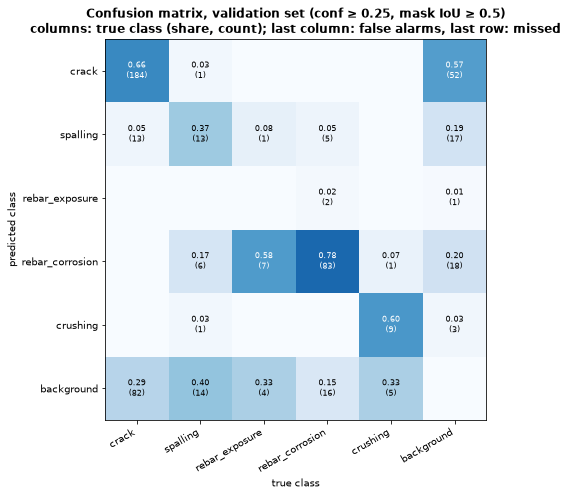

In [16]:
plot_confusion(confusion_from_cache(val_cache, DIAG_THRESHOLD),
               f"Confusion matrix, validation set (conf ≥ {DIAG_THRESHOLD}, mask IoU ≥ 0.5)\n"
               "columns: true class (share, count); last column: false alarms, last row: missed", "05_confusion_matrix_val", also_model_card=True)

**Reading the matrix (columns = true class):**
- **Cracks:** 66 % found, 29 % missed. They also cause most false alarms.
- **Exposed rebar is never recognised:** most of it is called *corrosion*. The two classes differ only by rust, and training has 628 corrosion but only 65 exposure polygons.
- **Spalling** is missed 40 % of the time; crushing is found 60 % of the time.

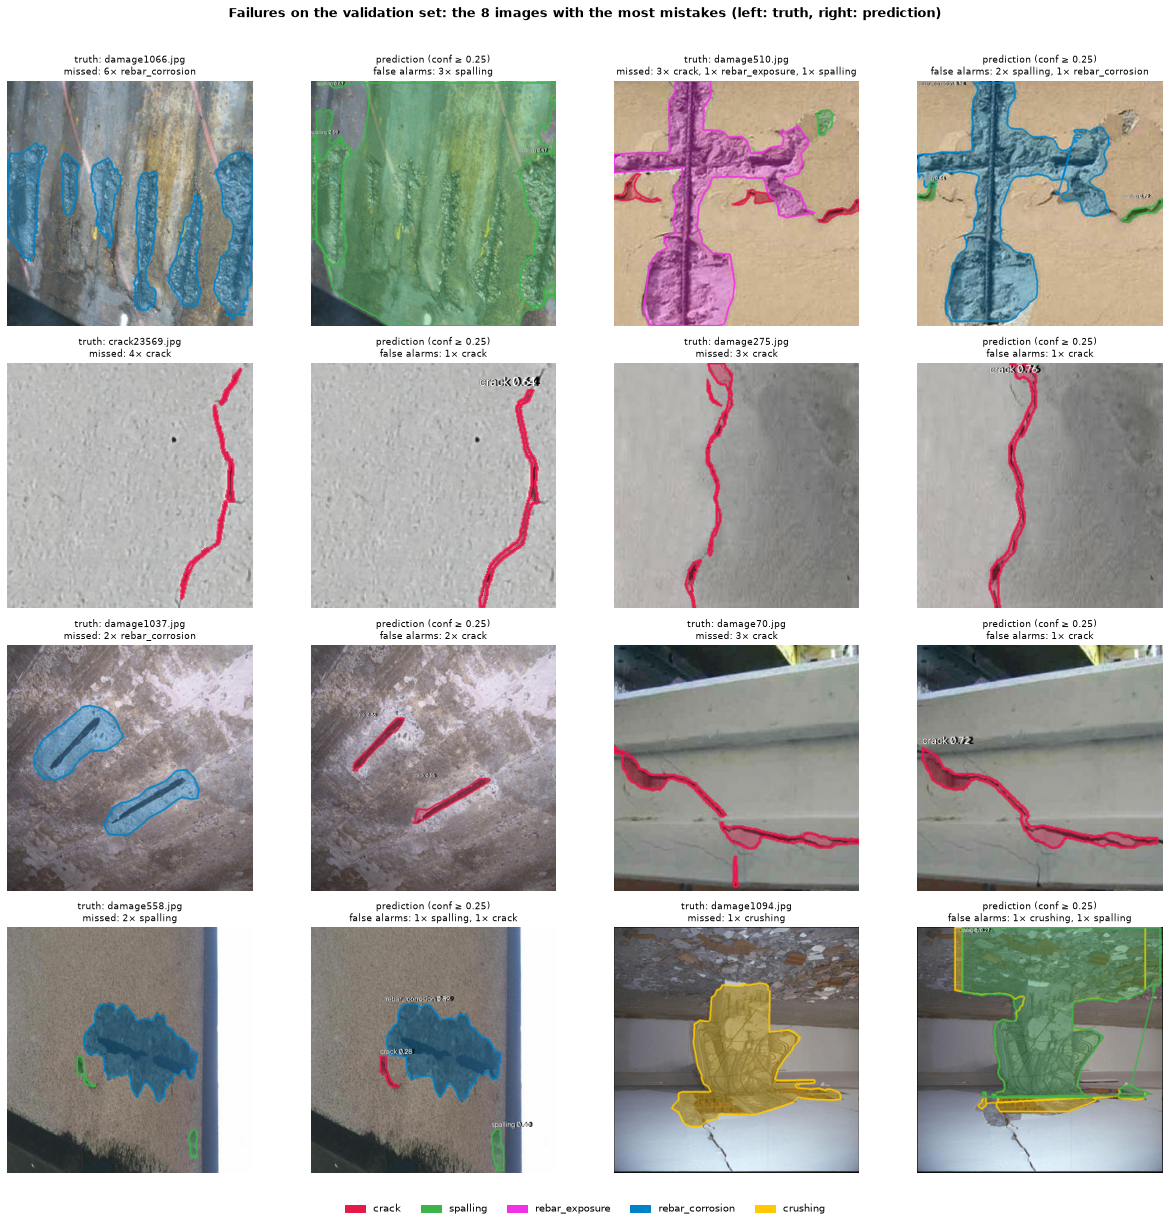

In [17]:
def draw_predictions(rgb, entry, threshold, keep_only=None):
    """Draw predicted outlines (class colour) with class and confidence labels."""
    keep = np.where(entry["conf"] >= threshold)[0] if keep_only is None else keep_only
    polys = [(entry["cls"][i], entry["polys"][i]) for i in keep if len(entry["polys"][i]) >= 3]
    out = draw_polygons(rgb, polys)
    for i in keep:
        if len(entry["polys"][i]) >= 3:
            x0, y0 = entry["polys"][i].min(axis=0)
            label = f"{CLASSES[entry['cls'][i]]} {entry['conf'][i]:.2f}"
            cv2.putText(out, label, (int(x0), max(int(y0) - 4, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 0), 3)
            cv2.putText(out, label, (int(x0), max(int(y0) - 4, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 255), 1)
    return out


def summarise(labels):
    """['crack', 'crack', 'spalling'] -> '2× crack, 1× spalling'"""
    return ", ".join(f"{n_}× {c}" for c, n_ in pd.Series(labels, dtype=str).value_counts().items())


def failure_gallery(cache, names, threshold, title, fig_name, also_model_card=False):
    rows = math.ceil(len(names) / 2)
    fig, axes = plt.subplots(rows, 4, figsize=(17, 4.3 * rows), squeeze=False)
    for k, name in enumerate(names):
        entry = cache[name]
        tp, keep, matched = match(entry, threshold)
        rgb = load_rgb(RAW_DIR / name, WORK_SIDE)
        ax_t, ax_p = axes.flat[2 * k], axes.flat[2 * k + 1]
        ax_t.imshow(draw_polygons(rgb, truth_polys(name, rgb.shape[:2])))
        missed = summarise([CLASSES[c] for c, m in zip(entry["true_cls"], matched) if not m])
        ax_t.set_title(f"truth: {name}" + (f"\nmissed: {missed}" if missed else "\nall found"), fontsize=9, fontweight="normal")
        ax_p.imshow(draw_predictions(rgb, entry, threshold))
        false_alarms = summarise([CLASSES[entry["cls"][i]] for f, i in zip(tp, keep) if not f])
        ax_p.set_title(f"prediction (conf ≥ {threshold})" + (f"\nfalse alarms: {false_alarms}" if false_alarms else "\nno false alarm"),
                       fontsize=9, fontweight="normal")
    for ax in axes.flat:
        ax.axis("off")
    fig.suptitle(title, fontsize=13, fontweight="bold")
    class_legend(fig, loc="lower center", fontsize=10)
    plt.tight_layout(rect=(0, 0.03, 1, 0.97))
    save_fig(fig_name, also_model_card, dpi=90)
    plt.show()


errors = {}
for name, entry in val_cache.items():
    tp, keep, matched = match(entry, DIAG_THRESHOLD)
    errors[name] = (~matched).sum() + (~tp).sum()
errors = pd.Series(errors).sort_values(ascending=False)
# the 8 validation images with the most mistakes, one per duplicate group
worst = images.set_index("image").loc[errors.index].assign(errors=errors.values).query("errors > 0").drop_duplicates("group").index[:8].tolist()
failure_gallery(val_cache, worst, DIAG_THRESHOLD,
                "Failures on the validation set: the 8 images with the most mistakes (left: truth, right: prediction)",
                "06_failures_val", also_model_card=True)

**What the failures have in common:**
- **Cut differently, not missed:** in several crack images the prediction lies right on the crack, but the annotator split it into 3–4 pieces. The metric then counts misses plus a false alarm. IoU ≥ 0.5 is harsh for thin cracks.
- **Ambiguous classes:** exposed rebar → corrosion, crushing → spalling, and the dark lines of bars → cracks.
- **One area vs many:** six annotated corroded bars are drawn as one large spalling area.

# 5. Tuning: image size 640 vs 416

One change: `imgsz=416` instead of 640, everything else identical. Our guess: thin cracks need the higher resolution. Compared on **validation**.

In [18]:
EXPERIMENT_RUN, EXPERIMENT_IMGSZ = "seg_n_416", 416
experiment_best, experiment_log = train_run(EXPERIMENT_RUN, EXPERIMENT_IMGSZ) if TRAIN else (None, None)

comparison, per_class_ap = {}, {}
for run, best, imgsz in [(MAIN_RUN, main_best, MAIN_IMGSZ), (EXPERIMENT_RUN, experiment_best, EXPERIMENT_IMGSZ)]:
    if best is None or not Path(best).exists():
        continue
    detector = YOLO(best)
    m = detector.val(data=str(DATA_YAML), split="val", imgsz=imgsz, device=YOLO_DEVICE, project=str(RUNS_DIR),
                     name=f"{run}_val", exist_ok=True, plots=False, verbose=False)
    log = pd.read_csv(RUNS_DIR / run / "results.csv")
    minutes_file = RUNS_DIR / run / "training_minutes.txt"
    comparison[f"imgsz {imgsz}"] = {"epochs trained": len(log), "training time (min)": float(minutes_file.read_text()) if minutes_file.exists() else np.nan,
                                    "inference (ms / image)": m.speed["inference"], "mask mAP50": m.seg.map50, "mask mAP50-95": m.seg.map,
                                    "box mAP50": m.box.map50}
    per_class_ap[f"imgsz {imgsz}"] = per_class_table(m)["mask AP50"]
comparison = pd.DataFrame(comparison).round(3)
pd.concat([comparison, pd.DataFrame(per_class_ap).reindex(CLASSES).round(3).rename(index=lambda c: f"{c} mask AP50")])

seg_n_416: reusing the finished run in /Users/luiswulf/Documents/IAAC/AI-Methods/Group4-day4-assignment/runs/seg_n_416 (trained in 32 min)
Ultralytics 8.4.210 🚀 Python-3.12.10 torch-2.15.0 MPS (Apple M4)


YOLO26n-seg summary (fused): 137 layers, 2,704,755 parameters, 0 gradients, 9.1 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 529.9±337.8 MB/s, size: 28.4 KB)


val: Scanning /Users/luiswulf/Documents/IAAC/AI-Methods/Group4-day4-assignment/data/yolo.nosync/labels/val.cache... 303 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 303/303 317.7Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 5% ╸─────────── 1/19 1.2s/it 0.4s<21.1s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 10% ━─────────── 2/19 1.9it/s 0.6s<9.0s

... (41 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 5.5it/s 3.4s

                   all        303        447      0.572      0.535      0.567      0.392      0.567      0.536      0.537       0.36


Speed: 0.1ms preprocess, 1.5ms inference, 0.0ms loss, 5.6ms postprocess per image


,imgsz 640,imgsz 416
epochs trained,50.000,35.000
training time (min),90.400,32.200
inference (ms / image),1.420,1.525
mask mAP50,0.561,0.537
mask mAP50-95,0.396,0.360
box mAP50,0.591,0.567
crack mask AP50,0.761,0.757
spalling mask AP50,0.465,0.336
rebar_exposure mask AP50,0.181,0.224
rebar_corrosion mask AP50,0.801,0.785


**Result:** 416 px loses 0.024 mask mAP50 but trains **2.8 × faster** (32 vs 90 min). Our guess was wrong for cracks: same AP (0.76) at both sizes, because many crack images are only 227 px wide. The gap comes from spalling (35 polygons, partly noise). **We keep 640 px.**

In [19]:
# The final model: 640 px, chosen on validation above (before looking at the test set)
FINAL_RUN, FINAL_BEST, FINAL_IMGSZ = MAIN_RUN, main_best, MAIN_IMGSZ
final, final_val_cache = model, val_cache
print(f"final model: {FINAL_RUN} (imgsz {FINAL_IMGSZ})")

final model: seg_n_640 (imgsz 640)


# 6. Threshold, then the test set, once

## 6.1 Choosing the confidence threshold (validation)
Rule: **the lowest threshold where at least 70 % of the flagged outlines are real damage** (precision ≥ 0.70). Lower thresholds give more recall, but with more than 30 % false alarms the engineer would check everything anyway.

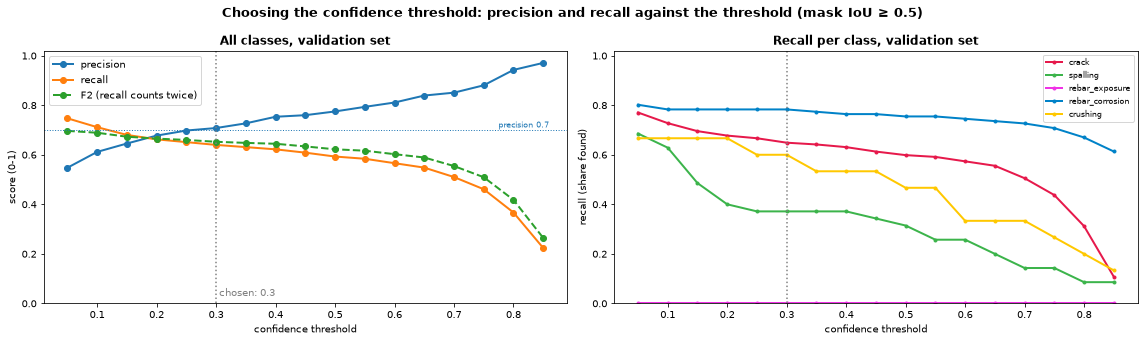

,precision,recall,F2,false alarms,missed
threshold,,,,,
0.05,0.548,0.747,0.696,276,113
0.10,0.612,0.711,0.689,202,129
0.15,0.645,0.680,0.673,167,143
0.20,0.677,0.662,0.665,141,151
0.25,0.698,0.651,0.660,126,156
0.30,0.708,0.640,0.652,118,161
0.35,0.727,0.631,0.648,106,165
0.40,0.753,0.622,0.644,91,169
0.50,0.775,0.593,0.622,77,182


In [20]:
thresholds = np.round(np.arange(0.05, 0.86, 0.05), 2)
sweep_rows = []
for t in thresholds:
    c = counts_at(final_val_cache, t)
    for cls_name in CLASSES + ["all"]:
        r = c.sum() if cls_name == "all" else c.loc[cls_name]
        p, rec = r["found"] / max(r["found"] + r["false alarms"], 1), r["found"] / max(r["found"] + r["missed"], 1)
        sweep_rows.append({"threshold": t, "class": cls_name, "precision": p, "recall": rec,
                           "F2": 5 * p * rec / max(4 * p + rec, 1e-9), "false alarms": r["false alarms"], "missed": r["missed"]})
sweep = pd.DataFrame(sweep_rows)
overall = sweep[sweep["class"] == "all"].set_index("threshold")
MIN_PRECISION = 0.70
THRESHOLD = float(overall.index[overall.precision >= MIN_PRECISION].min())

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
axes[0].plot(overall.index, overall.precision, marker="o", lw=2, label="precision")
axes[0].plot(overall.index, overall.recall, marker="o", lw=2, label="recall")
axes[0].plot(overall.index, overall.F2, marker="o", lw=2, ls="--", label="F2 (recall counts twice)")
axes[0].axhline(MIN_PRECISION, color="tab:blue", ls=":", lw=1)
axes[0].text(0.86, MIN_PRECISION + 0.01, f"precision {MIN_PRECISION}", color="tab:blue", ha="right", fontsize=8)
axes[0].axvline(THRESHOLD, color="grey", ls=":")
axes[0].text(THRESHOLD, 0.03, f" chosen: {THRESHOLD}", color="grey")
axes[0].set(title="All classes, validation set", xlabel="confidence threshold", ylabel="score (0-1)", ylim=(0, 1.02))
axes[0].legend()
for k, cls_name in enumerate(CLASSES):
    part = sweep[sweep["class"] == cls_name]
    axes[1].plot(part.threshold, part.recall, marker=".", lw=2, color=np.array(COLOURS[k]) / 255, label=cls_name)
axes[1].axvline(THRESHOLD, color="grey", ls=":")
axes[1].set(title="Recall per class, validation set", xlabel="confidence threshold", ylabel="recall (share found)", ylim=(0, 1.02))
axes[1].legend(fontsize=8)
fig.suptitle("Choosing the confidence threshold: precision and recall against the threshold (mask IoU ≥ 0.5)", fontsize=13, fontweight="bold")
plt.tight_layout()
save_fig("07_threshold_sweep", also_model_card=True)
plt.show()
overall.loc[[t for t in [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5, 0.6] if t in overall.index]].drop(columns="class").round(3)

**Reading the sweep:**
- Pure F2 (recall counts twice) would pick 0.05, with 45 % wrong outlines. Our rule gives **0.30**: precision 0.71, recall 0.64 on validation.
- Exposed rebar has recall 0 at **every** threshold. No threshold fixes that, only more examples.

## 6.2 The test set (303 images), once

In [21]:
test_metrics = final.val(data=str(DATA_YAML), split="test", imgsz=FINAL_IMGSZ, device=YOLO_DEVICE, project=str(RUNS_DIR),
                         name=f"{FINAL_RUN}_test", exist_ok=True, plots=True, verbose=False)
test_cache = predict_cache(final, test_names, FINAL_IMGSZ)
test_counts = counts_at(test_cache, THRESHOLD)
test_per_class = per_class_table(test_metrics)
test_per_class[f"found (conf ≥ {THRESHOLD})"] = test_counts["found"]
test_per_class[f"missed"] = test_counts["missed"]
test_per_class[f"false alarms"] = test_counts["false alarms"]
total = test_counts.sum()
print(f"TEST SET: mask mAP50 = {test_metrics.seg.map50:.3f}, mask mAP50-95 = {test_metrics.seg.map:.3f}, "
      f"box mAP50 = {test_metrics.box.map50:.3f}, box mAP50-95 = {test_metrics.box.map:.3f}")
print(f"At the chosen threshold {THRESHOLD}: precision {total['found'] / (total['found'] + total['false alarms']):.3f}, "
      f"recall {total['found'] / (total['found'] + total['missed']):.3f} "
      f"({total['found']} found, {total['missed']} missed, {total['false alarms']} false alarms)")
test_per_class

Ultralytics 8.4.210 🚀 Python-3.12.10 torch-2.15.0 MPS (Apple M4)


YOLO26n-seg summary (fused): 137 layers, 2,704,755 parameters, 0 gradients, 9.1 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 50.8±39.0 MB/s, size: 7.7 KB)


val: Scanning /Users/luiswulf/Documents/IAAC/AI-Methods/Group4-day4-assignment/data/yolo.nosync/labels/test... 303 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 303/303 6.2Kit/s 0.0s

val: New cache created: /Users/luiswulf/Documents/IAAC/AI-Methods/Group4-day4-assignment/data/yolo.nosync/labels/test.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 5% ╸─────────── 1/19 1.0it/s 0.3s<17.5s

... (21 outputs left out)

Speed: 0.2ms preprocess, 1.3ms inference, 0.0ms loss, 9.0ms postprocess per image


Results saved to /Users/luiswulf/Documents/IAAC/AI-Methods/Group4-day4-assignment/runs/seg_n_640_test


TEST SET: mask mAP50 = 0.478, mask mAP50-95 = 0.301, box mAP50 = 0.540, box mAP50-95 = 0.341
At the chosen threshold 0.3: precision 0.750, recall 0.685 (300 found, 138 missed, 100 false alarms)


,mask precision,mask recall,mask AP50,mask AP50-95,box AP50,found (conf ≥ 0.3),missed,false alarms
crack,0.843,0.767,0.832,0.503,0.816,214,69,40
spalling,0.343,0.176,0.282,0.161,0.284,7,27,16
rebar_exposure,0.264,0.329,0.277,0.201,0.277,2,10,13
rebar_corrosion,0.741,0.735,0.775,0.517,0.783,74,24,26
crushing,0.416,0.273,0.223,0.122,0.539,3,8,5


In [22]:
def model_masks(cache, threshold):
    def predict(name, rgb):
        entry, out = cache[name], {}
        for i in np.where(entry["conf"] >= threshold)[0]:
            if len(entry["polys"][i]) >= 3:
                m = out.setdefault(int(entry["cls"][i]), np.zeros(entry["shape"], np.uint8))
                cv2.fillPoly(m, [entry["polys"][i]], 1)
        return {k: v.astype(bool) for k, v in out.items()}
    return predict


rule_test = pixel_iou(test_names, rule_masks, classes=[0, 3])
model_test_iou = pixel_iou(test_names, model_masks(test_cache, THRESHOLD))
baseline_table = pd.DataFrame({
    "pretrained COCO model: mask AP50": {c: 0.0 for c in CLASSES},
    "fine-tuned: mask AP50": test_per_class["mask AP50"],
    "rules: pixel IoU": {CLASSES[0]: rule_test["crack"], CLASSES[3]: rule_test["rebar_corrosion"]},
    "fine-tuned: pixel IoU": model_test_iou,
}).reindex(CLASSES)
baseline_table.round(3)

,pretrained COCO model: mask AP50,fine-tuned: mask AP50,rules: pixel IoU,fine-tuned: pixel IoU
crack,0.0,0.832,0.199,0.772
spalling,0.0,0.282,NaN,0.198
rebar_exposure,0.0,0.277,NaN,0.072
rebar_corrosion,0.0,0.775,0.115,0.641
crushing,0.0,0.223,NaN,0.401


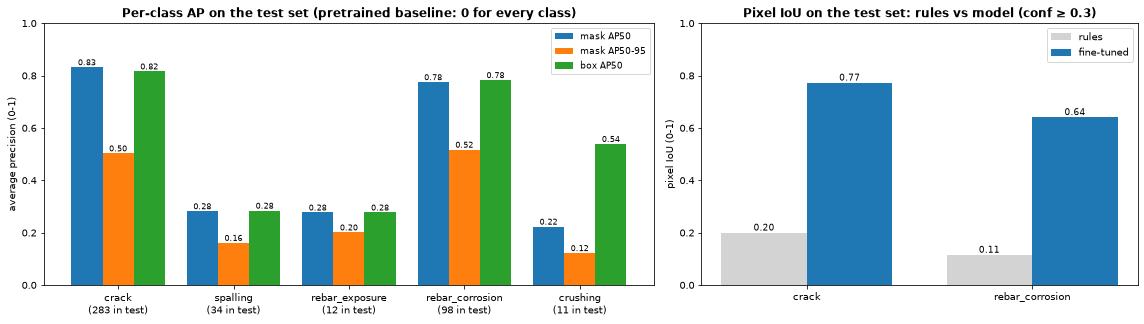

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})
x = np.arange(len(CLASSES))
for i, (col, label) in enumerate([("mask AP50", "mask AP50"), ("mask AP50-95", "mask AP50-95"), ("box AP50", "box AP50")]):
    bars = axes[0].bar(x + (i - 1) * 0.27, test_per_class[col].reindex(CLASSES), width=0.27, label=label)
    axes[0].bar_label(bars, fmt="%.2f", fontsize=8)
axes[0].axhline(0, color="black", lw=1)
axes[0].set_xticks(x, [f"{c}\n({int(table.loc[c, 'test'])} in test)" for c in CLASSES])
axes[0].set(ylabel="average precision (0-1)", ylim=(0, 1), title="Per-class AP on the test set (pretrained baseline: 0 for every class)")
axes[0].legend(fontsize=9)
pix = baseline_table.loc[["crack", "rebar_corrosion"], ["rules: pixel IoU", "fine-tuned: pixel IoU"]]
for i, col in enumerate(pix.columns):
    bars = axes[1].bar(np.arange(2) + (i - 0.5) * 0.38, pix[col], width=0.38, label=col.replace(": pixel IoU", ""),
                       color=["lightgrey", "tab:blue"][i])
    axes[1].bar_label(bars, fmt="%.2f", fontsize=9)
axes[1].set_xticks(np.arange(2), pix.index)
axes[1].set(ylabel="pixel IoU (0-1)", ylim=(0, 1), title=f"Pixel IoU on the test set: rules vs model (conf ≥ {THRESHOLD})")
axes[1].legend()
plt.tight_layout()
save_fig("08_test_per_class", also_model_card=True)
plt.show()

**Test results:**
- Mask mAP50 **0.48** (mAP50-95 0.30), lower than on validation (0.56); all choices were made on validation, so this is the honest number.
- **Baselines:** pretrained model 0 for every class; pixel IoU **0.77 vs 0.20** (cracks) and **0.64 vs 0.11** (corrosion) against the rules.
- **Frequent classes work** (crack 0.83, corrosion 0.78), **rare ones do not** (spalling 0.28, exposed rebar 0.28, crushing 0.22), with only 11–34 test polygons each.
- **At threshold 0.30:** precision 0.75, recall 0.69.

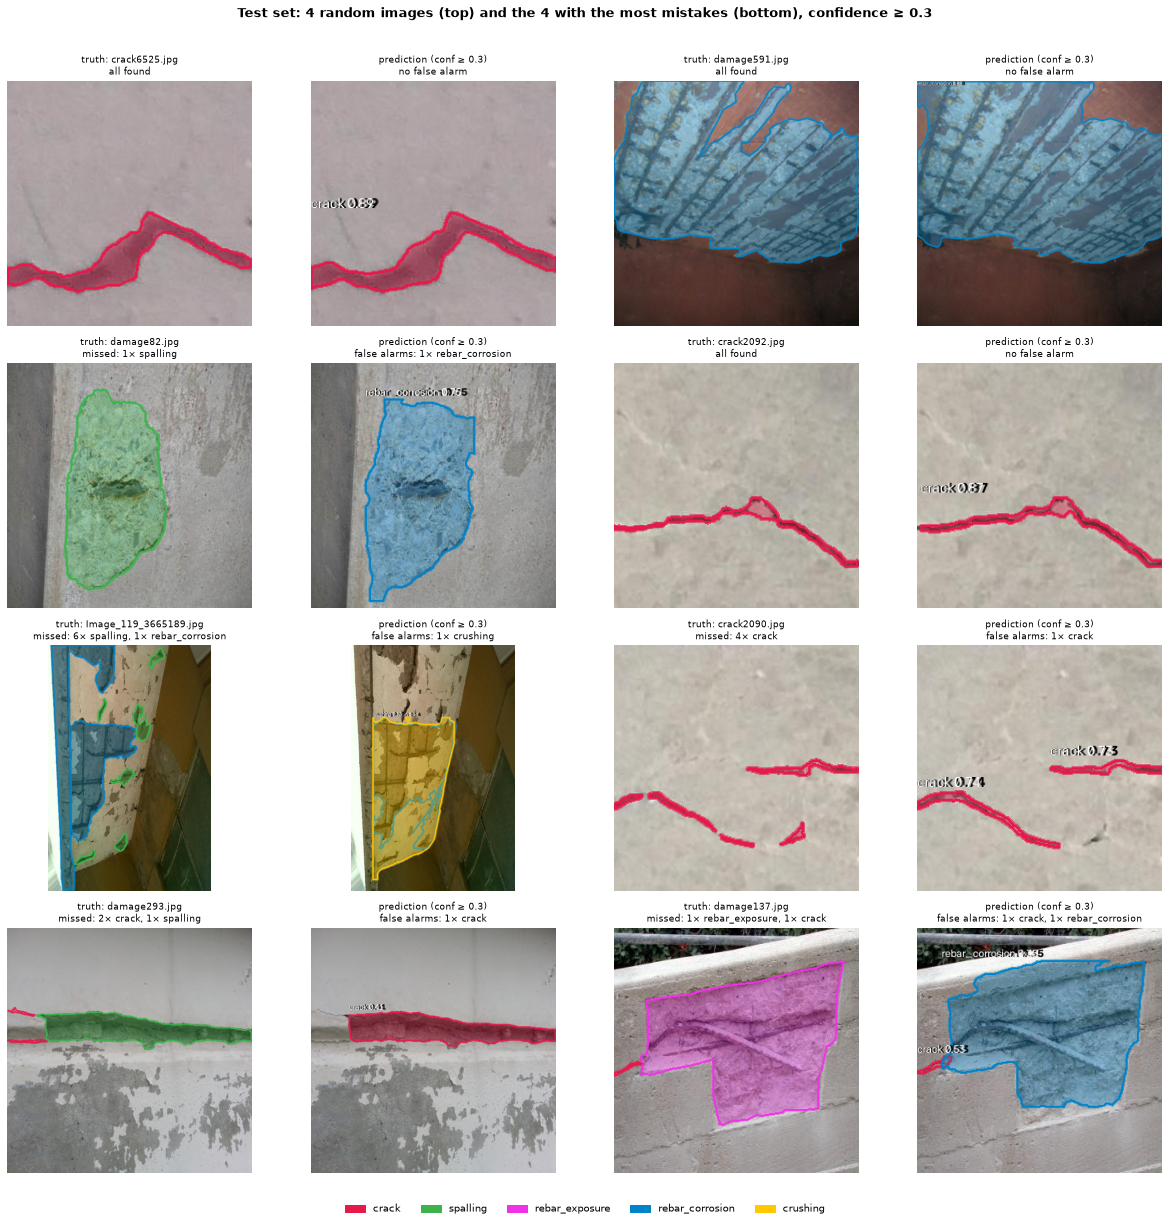

In [24]:
# Truth vs prediction on the test set: 4 random test images and the 4 with the most mistakes (one per duplicate group)
test_errors = {}
for name, entry in test_cache.items():
    tp, keep, matched = match(entry, THRESHOLD)
    test_errors[name] = (~matched).sum() + (~tp).sum()
test_errors = pd.Series(test_errors).sort_values(ascending=False)
worst_test = images.set_index("image").loc[test_errors.index].assign(errors=test_errors.values).query("errors > 0").drop_duplicates("group").index[:4].tolist()
random_test = [n_ for n_ in rng.choice(test_names, 12, replace=False) if n_ not in worst_test][:4]
failure_gallery(test_cache, random_test + worst_test, THRESHOLD,
                f"Test set: 4 random images (top) and the 4 with the most mistakes (bottom), confidence ≥ {THRESHOLD}",
                "09_test_predictions", also_model_card=True)

**What we see:** the 4 random images are segmented well. The 4 worst repeat the validation mistakes: right outline with wrong class (spalling → corrosion, exposed bar → corrosion, peeling → crushing) and cracks cut differently from the annotation.

# 7. Application: which bridge photos first?

46 photos of a damaged concrete motorway bridge (QEW, Niagara Falls) by Achim Hering, Wikimedia Commons, **CC BY 3.0**. We drop photos that are already in the dataset (CNN similarity ≥ 0.90), run the model at 0.30 and **rank** the photos by the most severe damage: crushing > rebar > spalling > crack. No ground truth: we check the ranking by eye.

In [25]:
NEW_DIR = DATA_DIR / "new_images" / "qew_bridge"
NEW_DIR.mkdir(parents=True, exist_ok=True)
COMMONS = "https://commons.wikimedia.org/wiki/Special:FilePath/Qew_bruecke_nf_beton_kaputt_{:02d}_von_46.jpg?width=1280"
for i in range(1, 47):
    target = NEW_DIR / f"qew_{i:02d}.jpg"
    if not target.exists():
        response = requests.get(COMMONS.format(i), headers={"User-Agent": "Mozilla/5.0 (IAAC course project)"}, timeout=60)
        response.raise_for_status()
        target.write_bytes(response.content)
        time.sleep(1.0)   # be polite to Wikimedia
new_names = sorted(p.name for p in NEW_DIR.glob("qew_*.jpg"))

with torch.no_grad():   # are they new? CNN similarity to every image of the dataset
    new_features = torch.nn.functional.normalize(encoder(torch.stack(
        [preprocess(Image.open(NEW_DIR / n_).convert("RGB")) for n_ in new_names]).to(DEVICE)), dim=-1).cpu().numpy()
similarity_to_dataset = np.einsum("qd,itd->qit", new_features, features).max(axis=2)   # over the 8 transforms
closest_in_dataset = similarity_to_dataset.max(axis=1)
already_seen = closest_in_dataset >= CNN_THRESHOLD_DAMAGE
for q in np.where(already_seen)[0]:
    j = similarity_to_dataset[q].argmax()
    print(f"{new_names[q]} is already in the dataset: {images.image[j]} ({images.split[j]} split), similarity {closest_in_dataset[q]:.3f}")
new_names = [n_ for n_, seen in zip(new_names, already_seen) if not seen]
print(f"-> {len(new_names)} bridge photos are new; the highest similarity of these to any dataset image is "
      f"{closest_in_dataset[~already_seen].max():.3f}")

SEVERITY = {"crushing": 4, "rebar_exposure": 3, "rebar_corrosion": 3, "spalling": 2, "crack": 1}
new_cache = predict_cache(final, new_names, FINAL_IMGSZ, folder=NEW_DIR, with_truth=False)
report = []
for name, entry in new_cache.items():
    keep = [i for i in np.where(entry["conf"] >= THRESHOLD)[0] if len(entry["polys"][i]) >= 3]
    found = pd.Series([CLASSES[entry["cls"][i]] for i in keep], dtype=str).value_counts()
    covered = np.zeros(entry["shape"], np.uint8)
    for i in keep:
        cv2.fillPoly(covered, [entry["polys"][i]], 1)
    worst_found = max(found.index, key=SEVERITY.get) if len(found) else "none"
    report.append({"photo": name, "most severe": worst_found, "severity": SEVERITY.get(worst_found, 0),
                   "damage share of photo": covered.mean(), **{c: int(found.get(c, 0)) for c in CLASSES}})
report = pd.DataFrame(report).sort_values(["severity", "damage share of photo"], ascending=False).reset_index(drop=True)
report.index += 1
report["check"] = np.where(report.severity >= 3, "1 engineer first", np.where(report.severity >= 1, "2 later", "3 no damage found"))
print(report.check.value_counts().sort_index().to_string())
report.head(12).round(3)

qew_25.jpg is already in the dataset: damage381.jpg (test split), similarity 0.937
qew_34.jpg is already in the dataset: corrosion_262.jpg (train split), similarity 0.995
-> 44 bridge photos are new; the highest similarity of these to any dataset image is 0.833


check
1 engineer first      4
2 later              14
3 no damage found    26


,photo,most severe,severity,damage share of photo,crack,spalling,rebar_exposure,rebar_corrosion,crushing,check
1,qew_21.jpg,crushing,4,0.062,0,0,0,0,1,1 engineer first
2,qew_24.jpg,rebar_corrosion,3,0.126,0,0,0,1,0,1 engineer first
3,qew_37.jpg,rebar_corrosion,3,0.044,0,0,0,1,0,1 engineer first
4,qew_29.jpg,rebar_corrosion,3,0.022,0,0,0,2,0,1 engineer first
5,qew_36.jpg,spalling,2,0.010,0,2,0,0,0,2 later
6,qew_26.jpg,spalling,2,0.007,0,2,0,0,0,2 later
7,qew_08.jpg,spalling,2,0.004,0,1,0,0,0,2 later
8,qew_16.jpg,spalling,2,0.003,0,1,0,0,0,2 later
9,qew_42.jpg,spalling,2,0.003,0,1,0,0,0,2 later
10,qew_33.jpg,spalling,2,0.002,0,1,0,0,0,2 later


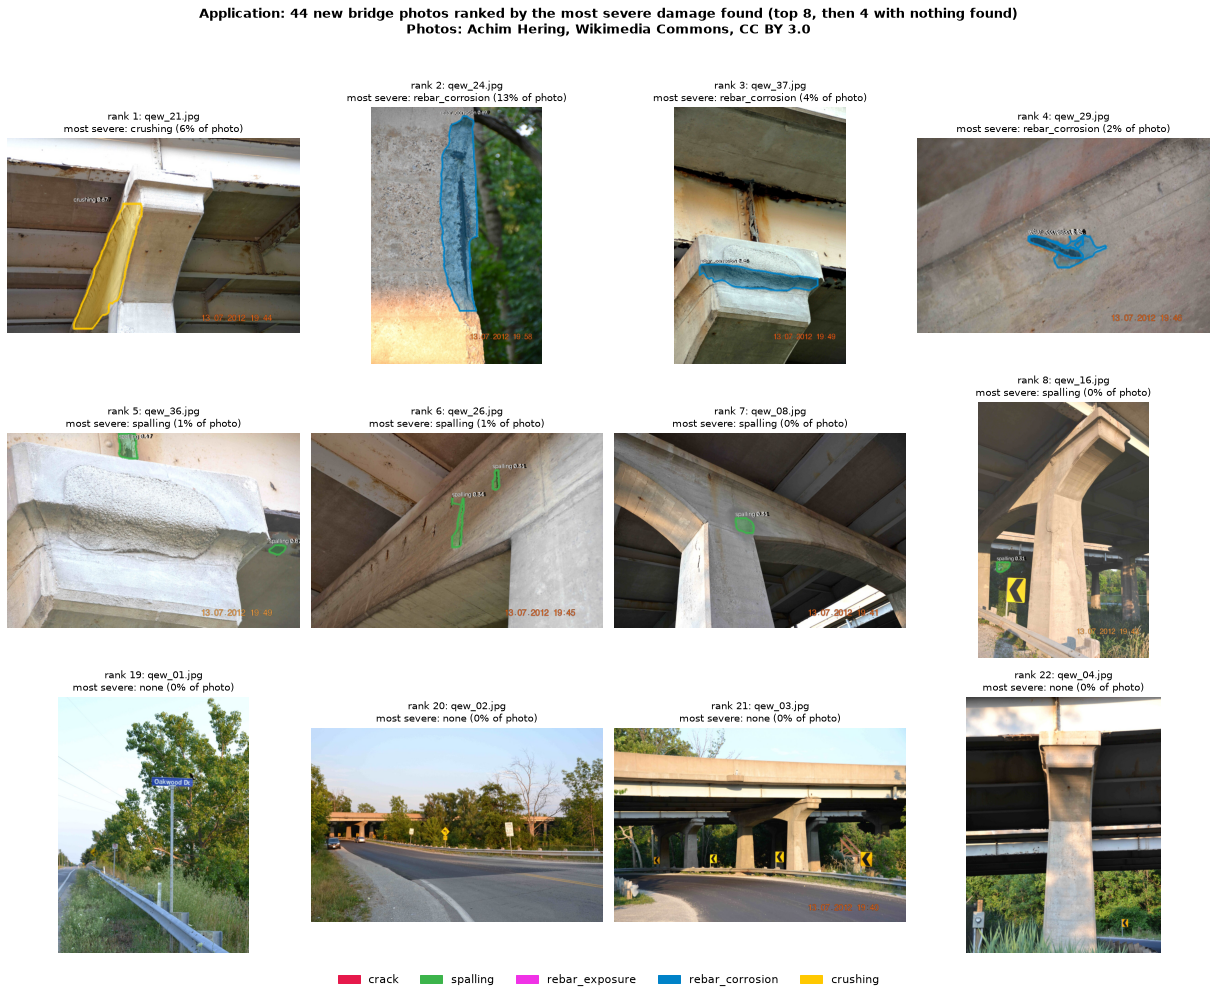

In [26]:
shown = report.head(8).photo.tolist() + report[report.severity == 0].photo.head(4).tolist()
if len(shown) < 12:
    shown += [p for p in report.photo[::-1] if p not in shown][: 12 - len(shown)]
fig, axes = plt.subplots(3, 4, figsize=(17, 14))
for ax, name in zip(axes.flat, shown):
    rgb = load_rgb(NEW_DIR / name, WORK_SIDE)
    ax.imshow(draw_predictions(rgb, new_cache[name], THRESHOLD))
    r = report.loc[report.photo == name].iloc[0]
    ax.set_title(f"rank {r.name}: {name}\nmost severe: {r['most severe']} ({r['damage share of photo']:.0%} of photo)", fontsize=10, fontweight="normal")
    ax.axis("off")
fig.suptitle(f"Application: {len(new_names)} new bridge photos ranked by the most severe damage found (top 8, then 4 with nothing found)\n"
             f"Photos: Achim Hering, Wikimedia Commons, CC BY 3.0", fontsize=13, fontweight="bold")
class_legend(fig, loc="lower center", fontsize=11)
plt.tight_layout(rect=(0, 0.03, 1, 0.96))
save_fig("10_application_bridge", also_model_card=True, dpi=90)
plt.show()

**Checking the ranking by eye:**
- **Right:** ranks 2 and 4 (spalling with corroded rebar); overview photos empty; cracks ranked "later".
- **Wrong:** rank 1 is a shadowed, intact pier edge called *crushing*; rust stains from a steel girder are called corrosion.
- **Dangerous miss:** `qew_23` (clearly exposed, corroded bars) lands in "no damage found".

So the model can **sort** a photo series, but "no damage found" does not mean "no damage".

# 8. Save, reload and use
`best.pt` → `../models/model.pt` (uploaded to Hugging Face, not committed), plus the training log. Then reload and predict as a user would.

In [27]:
shutil.copy2(FINAL_BEST, MODEL_DIR / "model.pt")
shutil.copy2(RUNS_DIR / FINAL_RUN / "results.csv", MODEL_DIR / "results.csv")
print({p.name: f"{p.stat().st_size / 1e6:.1f} MB" for p in sorted(MODEL_DIR.iterdir()) if p.is_file()})

reloaded = YOLO(MODEL_DIR / "model.pt")
example = NEW_DIR / report.photo.iloc[0]
result = reloaded.predict(str(example), conf=THRESHOLD, imgsz=FINAL_IMGSZ, device=YOLO_DEVICE, verbose=False)[0]
print(f"{example.name}: {len(result.boxes)} damage outlines:",
      [f"{reloaded.names[int(c)]} {p:.2f}" for c, p in zip(result.boxes.cls, result.boxes.conf)])
assert np.allclose(result.boxes.conf.cpu().numpy()[:3], final.predict(str(example), conf=THRESHOLD, imgsz=FINAL_IMGSZ,
                   device=YOLO_DEVICE, verbose=False)[0].boxes.conf.cpu().numpy()[:3], atol=1e-4), "reloaded model differs"
print("The reloaded model gives the same predictions.")

{'04_training_curves.png': '0.2 MB', '05_confusion_matrix_val.png': '0.1 MB', '06_failures_val.png': '2.0 MB', '07_threshold_sweep.png': '0.1 MB', '08_test_per_class.png': '0.1 MB', '09_test_predictions.png': '1.7 MB', '10_application_bridge.png': '1.9 MB', 'README.md': '0.0 MB', 'model.pt': '6.6 MB', 'results.csv': '0.0 MB'}
qew_21.jpg: 1 damage outlines: ['crushing 0.67']
The reloaded model gives the same predictions.


# 9. Conclusions

### Key findings
- **Clearly better than both baselines:** test mask mAP50 **0.48** vs 0 (pretrained); pixel IoU **0.77 vs 0.20** (cracks) and **0.64 vs 0.11** (corrosion) vs the rules.
- **Good on frequent classes, weak on rare ones:** crack 0.83, corrosion 0.78; spalling 0.28, exposed rebar 0.28, crushing 0.22. The most severe classes are the weakest.
- **The dataset is full of copies:** 77 % of the images are in a duplicate group. Without grouping, the test would have measured memory.
- **Threshold 0.30** (precision ≥ 0.70 on validation): test precision 0.75, recall 0.69.
- **640 vs 416 px:** +0.024 mask mAP50 for 2.8 × training time.
- **Bridge photos:** the ranking is partly useful, but one false alarm is ranked first and one severe photo is missed.

### Limitations
- **Data:** unnamed sources, mixed resolutions, no scale; two of our "new" bridge photos were in the dataset. Many test crack close-ups resemble training photos, so the crack score is optimistic for a new building.
- **Annotation:** inconsistent (one crack vs several pieces; exposed vs corroded rebar).
- **Small numbers:** 11–35 polygons per rare class in validation and test; one run per setting.
- **Not for:** structural assessment, crack-width measurement, clearing photos without a human look, other materials or image types.